# RecycleIR — Computer Vision Product Verification

Notebook version of the supplied code. It extracts simple image features, compares a scanned image against registered products, and runs a synthetic original-versus-counterfeit demo.

**Dependencies:** `opencv-python`, `numpy`, and `matplotlib`.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time


## 1. Feature extraction and matching

The extractor combines a 64-value threshold hash, edge density, and color statistics. The matcher provides cosine similarity and Hamming distance.


In [2]:
class ComputerVisionExtractor:
    def __init__(self, hash_size=8):
        self.hash_size = hash_size

    def compute_phash(self, image_np):
        gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)
        resized = cv2.resize(
            gray,
            (self.hash_size, self.hash_size),
            interpolation=cv2.INTER_AREA,
        )
        avg = resized.mean()
        diff = resized > avg
        return diff.flatten().astype(int)

    def extract_edge_density(self, image_np):
        gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)
        edges = cv2.Canny(gray, 100, 200)
        edge_density = np.sum(edges > 0) / float(edges.size)
        return edge_density, edges

    def extract_feature_vector(self, image_np):
        phash_vec = self.compute_phash(image_np)
        edge_density, _ = self.extract_edge_density(image_np)
        color_mean = image_np.mean(axis=(0, 1)) / 255.0
        color_std = image_np.std(axis=(0, 1)) / 255.0
        combined_vector = np.concatenate(
            [phash_vec, [edge_density], color_mean, color_std]
        )
        return combined_vector


class VectorMatcher:
    @staticmethod
    def cosine_similarity(vec_a, vec_b):
        dot_product = np.dot(vec_a, vec_b)
        norm_a = np.linalg.norm(vec_a)
        norm_b = np.linalg.norm(vec_b)
        if norm_a == 0 or norm_b == 0:
            return 0.0
        return dot_product / (norm_a * norm_b)

    @staticmethod
    def hamming_distance(hash_a, hash_b):
        return np.sum(hash_a != hash_b)


## 2. RecycleIR verification engine

Registered products are stored in an in-memory list. A scan is compared with each registered product and the closest feature-vector match is returned with its metadata.


In [3]:
class RecycleIR_Engine:
    def __init__(self):
        self.db = []
        self.cv_processor = ComputerVisionExtractor()
        self.matcher = VectorMatcher()

    def register_genuine_product(
        self,
        product_id,
        name,
        category,
        image_np,
        safety_specs,
        recall_status=False,
    ):
        vec = self.cv_processor.extract_feature_vector(image_np)
        phash = self.cv_processor.compute_phash(image_np)
        product_record = {
            "product_id": product_id,
            "name": name,
            "category": category,
            "vector": vec,
            "phash": phash,
            "safety_specs": safety_specs,
            "is_safety_recalled": recall_status,
            "certified_alternatives": [],
        }
        self.db.append(product_record)

    def scan_and_verify(self, query_image_np, similarity_threshold=0.88):
        start_time = time.time()
        query_vec = self.cv_processor.extract_feature_vector(query_image_np)
        query_phash = self.cv_processor.compute_phash(query_image_np)

        best_match = None
        max_similarity = -1.0
        min_hamming = 999

        for record in self.db:
            sim = self.matcher.cosine_similarity(query_vec, record["vector"])
            h_dist = self.matcher.hamming_distance(query_phash, record["phash"])
            if sim > max_similarity:
                max_similarity = sim
                min_hamming = h_dist
                best_match = record

        latency_ms = (time.time() - start_time) * 1000
        is_genuine = max_similarity >= similarity_threshold
        result = {
            "match_found": best_match is not None,
            "similarity_score": round(float(max_similarity), 4),
            "hamming_distance": int(min_hamming),
            "latency_ms": round(latency_ms, 2),
            "verification_status": (
                "GENUINE_ORIGINAL" if is_genuine else "COUNTERFEIT_ALERT"
            ),
            "retrieved_metadata": None,
        }

        if best_match:
            result["retrieved_metadata"] = {
                "matched_product_name": best_match["name"],
                "category": best_match["category"],
                "registered_id": best_match["product_id"],
                "safety_standards": best_match["safety_specs"],
                "has_active_safety_recall": best_match["is_safety_recalled"],
                "action_recommendation": (
                    "Product matches safety standards."
                    if is_genuine
                    else "Warning: Counterfeit product detected. High safety risk."
                ),
            }

        return result


## 3. Synthetic sample images

These generated images are only for demonstrating the code; they are not real product images or a validated counterfeit detector.


In [4]:
def create_synthetic_image(pattern_type="genuine"):
    img = np.zeros((200, 200, 3), dtype=np.uint8) + 240

    if pattern_type == "genuine":
        cv2.rectangle(img, (20, 20), (180, 180), (0, 102, 204), 4)
        cv2.putText(
            img,
            "SAFE-VOLT",
            (30, 105),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 102, 204),
            2,
        )
        cv2.circle(img, (150, 150), 12, (0, 153, 76), -1)
    else:
        cv2.rectangle(img, (22, 18), (178, 182), (0, 80, 180), 2)
        cv2.putText(
            img,
            "SAFE-VOLT",
            (28, 107),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.78,
            (20, 20, 200),
            1,
        )
        cv2.circle(img, (148, 152), 10, (0, 100, 50), -1)
        noise = np.random.randint(0, 50, (200, 200, 3), dtype=np.uint8)
        img = cv2.add(img, noise)

    return img


## 4. Run the demonstration

Run this cell to register the synthetic original product, scan the altered image, print the result, and display both images.


Verification Status: GENUINE_ORIGINAL
Similarity Score: 0.9169
Hamming Distance: 6
Latency (ms): 5.19
Retrieved Metadata: {'matched_product_name': 'Circuit Breaker - SafeVolt 63A', 'category': 'Electrical Circuit Breakers', 'registered_id': 'CB-2026-X100', 'safety_standards': {'ISO': 'ISO-9001', 'Max_Temp': '85C', 'ShortCircuit_Rating': '10kA'}, 'has_active_safety_recall': False, 'action_recommendation': 'Product matches safety standards.'}


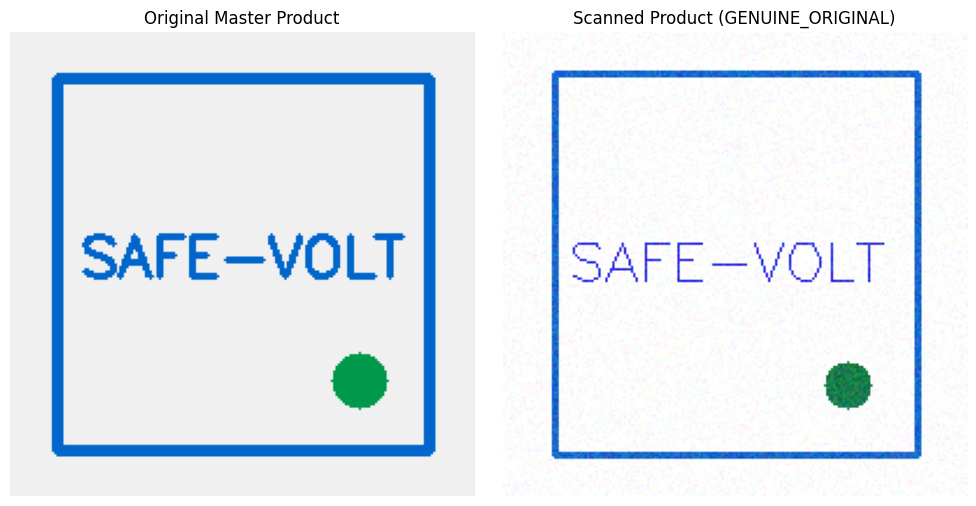

In [5]:
safescan_system = RecycleIR_Engine()

genuine_breaker_img = create_synthetic_image(pattern_type="genuine")
safescan_system.register_genuine_product(
    product_id="CB-2026-X100",
    name="Circuit Breaker - SafeVolt 63A",
    category="Electrical Circuit Breakers",
    image_np=genuine_breaker_img,
    safety_specs={
        "ISO": "ISO-9001",
        "Max_Temp": "85C",
        "ShortCircuit_Rating": "10kA",
    },
    recall_status=False,
)

fake_breaker_img = create_synthetic_image(pattern_type="counterfeit")
verification_output = safescan_system.scan_and_verify(
    fake_breaker_img,
    similarity_threshold=0.88,
)

print("Verification Status:", verification_output["verification_status"])
print("Similarity Score:", verification_output["similarity_score"])
print("Hamming Distance:", verification_output["hamming_distance"])
print("Latency (ms):", verification_output["latency_ms"])
print("Retrieved Metadata:", verification_output["retrieved_metadata"])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(genuine_breaker_img)
axes[0].set_title("Original Master Product")
axes[0].axis("off")

axes[1].imshow(fake_breaker_img)
axes[1].set_title(
    f"Scanned Product ({verification_output['verification_status']})"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()
